# XXZ模型：厳密対角化

XXZ模型の基底エネルギー$E_0$とスタッガード磁化$m_s(t)$を、厳密対角化で求める。手法の一般論は [methods/01_exact_diag.ipynb](../../methods/01_exact_diag.ipynb)、模型の定義は [00_model.ipynb](00_model.ipynb) を参照。

## 1. $n=2$の手計算

$n=2$（開放境界）のときの基底エネルギー$E_0$と、Néel状態$\ket{01}$からのスタッガード磁化$m_s(t)$を、[methods/01_exact_diag.ipynb](../../methods/01_exact_diag.ipynb)の2節・3節の式に従って手で計算する。

- **基底エネルギー$E_0$**

  $n=2$のときのハミルトニアンを行列表示する。基底の順は$\ket{00}, \ket{01}, \ket{10}, \ket{11}$である。

  $$
  \begin{aligned}
  X_0X_1 &= \begin{pmatrix}0&1\\1&0\end{pmatrix}\otimes\begin{pmatrix}0&1\\1&0\end{pmatrix} = \begin{pmatrix}0&0&0&1\\0&0&1&0\\0&1&0&0\\1&0&0&0\end{pmatrix},\quad
  Y_0Y_1 = \begin{pmatrix}0&-i\\i&0\end{pmatrix}\otimes\begin{pmatrix}0&-i\\i&0\end{pmatrix} = \begin{pmatrix}0&0&0&-1\\0&0&1&0\\0&1&0&0\\-1&0&0&0\end{pmatrix}, \\
  Z_0Z_1 &= \begin{pmatrix}1&0\\0&-1\end{pmatrix}\otimes\begin{pmatrix}1&0\\0&-1\end{pmatrix} = \begin{pmatrix}1&0&0&0\\0&-1&0&0\\0&0&-1&0\\0&0&0&1\end{pmatrix}
  \end{aligned}
  $$

  なので

  $$
  H = J\left(X_0X_1 + Y_0Y_1 + \Delta Z_0Z_1\right) =
  \begin{pmatrix}
  J\Delta & 0 & 0 & 0\\
  0 & -J\Delta & 2J & 0\\
  0 & 2J & -J\Delta & 0\\
  0 & 0 & 0 & J\Delta
  \end{pmatrix}
  $$

  となる。$X_0X_1$と$Y_0Y_1$の$\ket{00}\leftrightarrow\ket{11}$の成分は打ち消し合い、$\ket{01}\leftrightarrow\ket{10}$の成分だけが残る。行列は$\{\ket{00}\}$、$\{\ket{01}, \ket{10}\}$、$\{\ket{11}\}$のブロックに分かれている（全磁化の保存）。真ん中のブロックは$-J\Delta + 2J\sigma_x$の形なので、固有状態と固有値は

  $$
  \begin{aligned}
  \ket{\psi_-} &= \frac{\ket{01} - \ket{10}}{\sqrt{2}}: & E &= -2J - J\Delta \\
  \ket{\psi_+} &= \frac{\ket{01} + \ket{10}}{\sqrt{2}}: & E &= 2J - J\Delta \\
  \ket{00}, \ket{11}: & & E &= J\Delta
  \end{aligned}
  $$

  である。$\ket{\psi_-}$は**一重項**（全スピン0）、残りの3つは**三重項**（全スピン1）である。$\Delta>-1$では$-2J-J\Delta < J\Delta$なので、基底エネルギーは

  $$
  E_0 = -J(2 + \Delta)
  $$

  で、基底状態は一重項である。$\Delta=1$では三重項の3つの固有値がすべて$J$になり、SU(2)対称性による3重縮退が見える。

- **スタッガード磁化$m_s(t)$**

  $M_s = \frac{1}{2}(Z_0 - Z_1)$は$\ket{01}\to+1$、$\ket{10}\to-1$を返すので

  $$
  M_s\ket{\psi_\pm} = \ket{\psi_\mp}
  $$

  である。初期状態$\ket{01}$を固有状態で展開すると

  $$
  \ket{01} = \frac{1}{\sqrt{2}}\left(\ket{\psi_+} + \ket{\psi_-}\right),\quad c_+ = c_- = \frac{1}{\sqrt{2}}
  $$

  で、$\bra{\psi_\pm}M_s\ket{\psi_\pm} = 0$、$\bra{\psi_+}M_s\ket{\psi_-} = 1$なので

  $$
  \begin{aligned}
  m_s(t)
  &= \sum_{m, m'}c_m^*c_{m'}e^{i(E_m - E_{m'})t}\bra{m}M_s\ket{m'} \\
  &= c_+c_-\left(e^{i(E_+ - E_-)t} + e^{-i(E_+ - E_-)t}\right) \\
  &= \cos\left[(E_+ - E_-)t\right] \\
  &= \cos(4Jt)
  \end{aligned}
  $$

  となる。$E_+ - E_- = 4J$は$\Delta$によらないので、**$n=2$では$m_s(t)$は$\Delta$によらない**。$\ket{01}$と$\ket{10}$はどちらも$Z_0Z_1 = -1$なので、$ZZ$項はこの2状態に同じエネルギー$-J\Delta$を足すだけだからである。$\Delta$の効果が見えるのは、$\ket{1}$が隣り合ったり離れたりできる$n\ge3$からである。

## 2. コードで確かめる

一般の$n$に使える関数（`src/qmb/`）に$n=2$を代入して計算し、1節の手計算と比較する。

基底エネルギー E0 = -2.500000  (手計算: -J(2+Δ) = -2.500000)
基底状態 = [ 0.      +0.j  0.707107+0.j -0.707107+0.j  0.      +0.j]  (一重項 (|01> - |10>)/√2 に全体の位相を除いて一致)


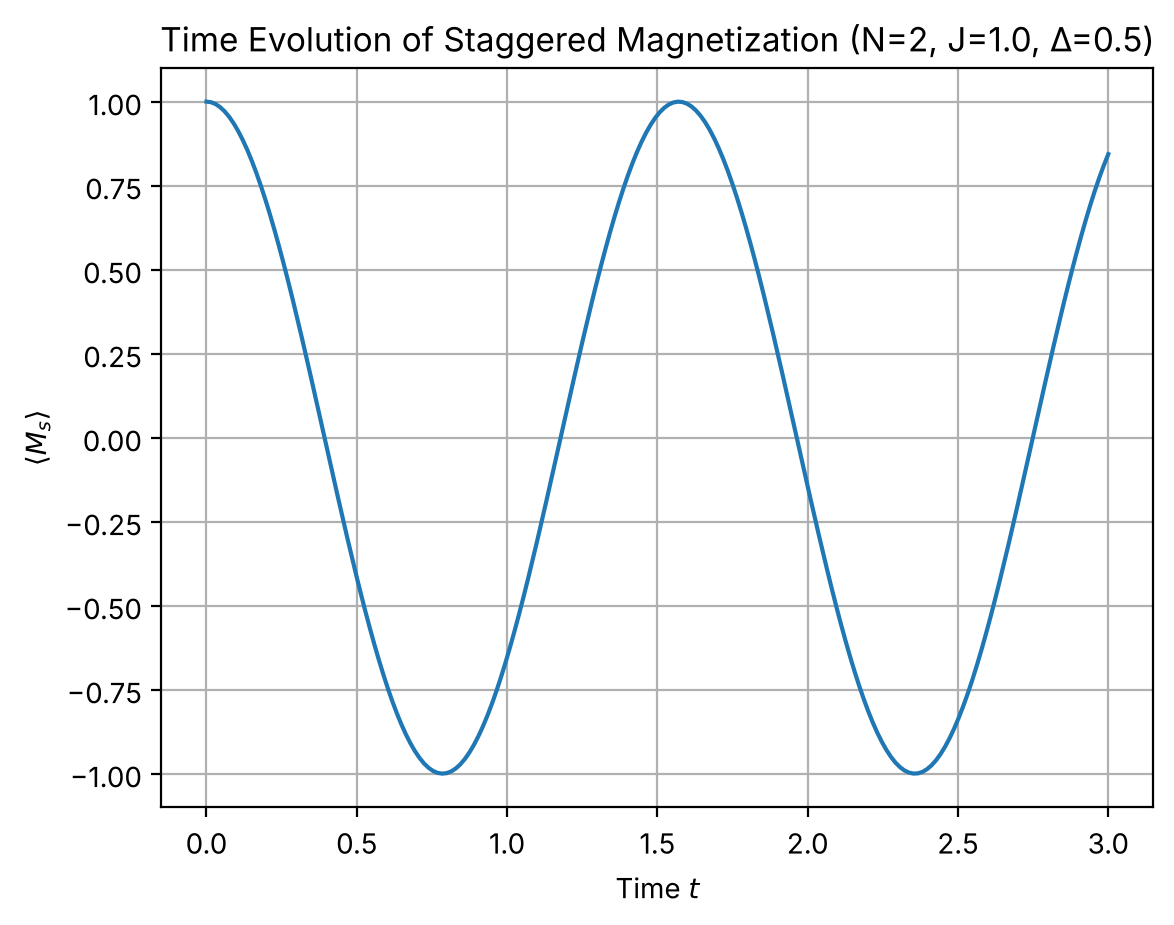

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 厳密対角化の計算に使う関数は共通パッケージ qmb から読み込む
#   neel_state                                  : src/qmb/operators.py
#   xxz_hamiltonian, staggered_magnetization    : src/qmb/models.py
#   ground_state, time_evolve_expectation       : src/qmb/ed.py
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: xxz_hamiltonian??）
from qmb.operators import neel_state
from qmb.models import xxz_hamiltonian as hamiltonian, staggered_magnetization
from qmb.ed import ground_state, time_evolve_expectation

# 例: N=2, J=1, Δ=0.5 の場合の基底状態と時間発展
N = 2
J = 1.0
Delta = 0.5
H = hamiltonian(N, J, Delta, pbc=False)   # N=2 は開放境界（周期境界だとボンドを2回数える）

# 基底エネルギー E_0
E0, psi_g = ground_state(H)
print(f"基底エネルギー E0 = {E0:.6f}  (手計算: -J(2+Δ) = {-J * (2 + Delta):.6f})")
print("基底状態 =", np.round(psi_g, 6), " (一重項 (|01> - |10>)/√2 に全体の位相を除いて一致)")

# m_s(t)
psi0 = neel_state(N)
A = staggered_magnetization(N)
ts = np.linspace(0, 3, 200)
expectations = time_evolve_expectation(H, psi0, A, ts)

# グラフ
plt.plot(ts, expectations)
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_s \rangle$")
plt.title(f"Time Evolution of Staggered Magnetization (N={N}, J={J}, Δ={Delta})")
plt.grid()
plt.show()

1節の手計算の結果と比較する。$J=1, \Delta=0.5$を代入すると

- **基底エネルギー$E_0$**
  $$
  E_0 = -J(2+\Delta) = -2.5
  $$
  コードの結果と一致している。
- **スタッガード磁化$m_s(t)$**
  $$
  m_s(t) = \cos(4Jt) = \cos 4t
  $$
  $\Delta$を変えても同じになることも含めて、グラフで比較する。

Δ=0.5: 手計算との最大誤差 = 6.7e-16
Δ=2.0: 手計算との最大誤差 = 5.6e-16


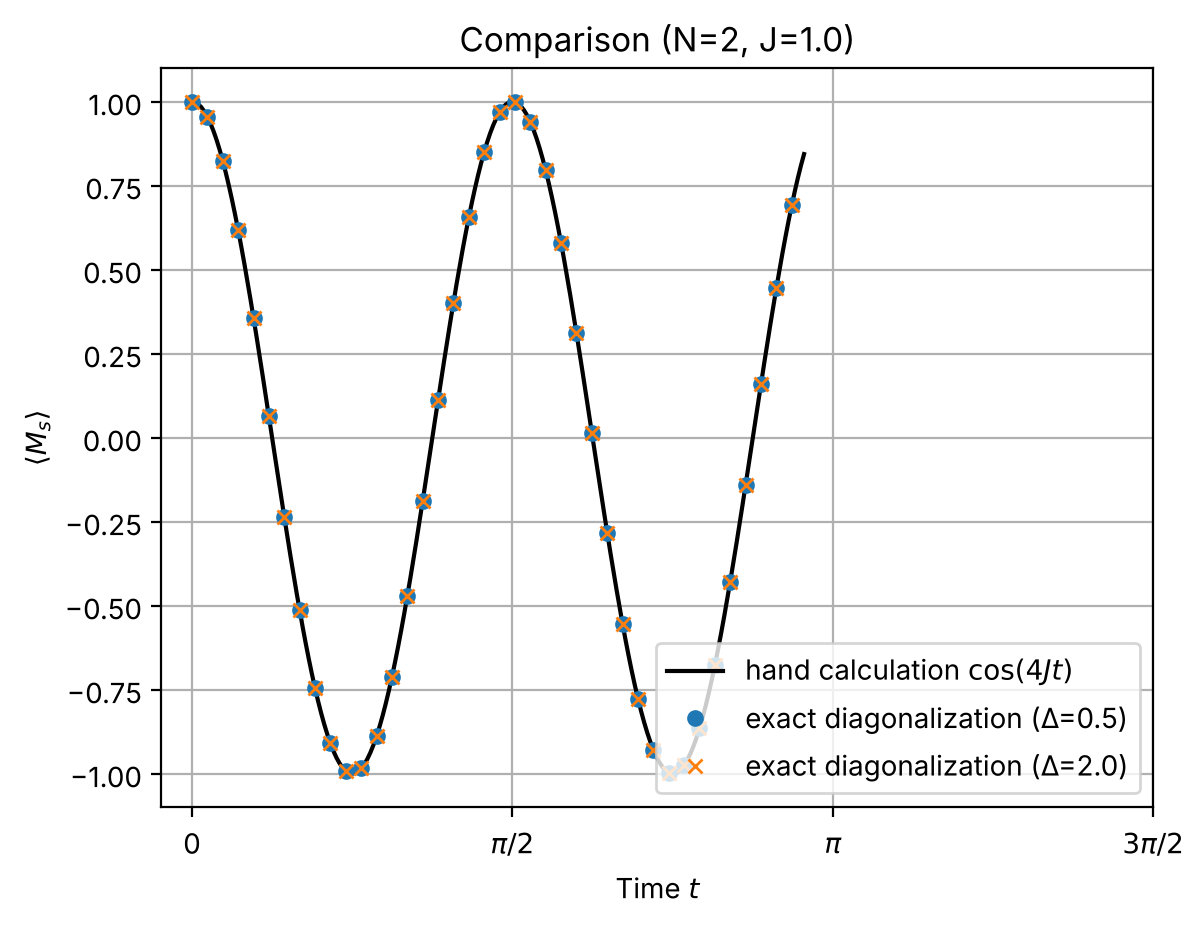

In [2]:
# m_s(t) = cos(4Jt)、Δ によらない
m_hand = np.cos(4 * J * ts)

T = np.pi / 2   # 周期 2π/(4J)
plt.plot(ts, m_hand, "k-", label=r"hand calculation $\cos(4Jt)$")
for D, mk in [(0.5, "o"), (2.0, "x")]:
    ms = time_evolve_expectation(hamiltonian(N, J, D), psi0, A, ts)
    print(f"Δ={D}: 手計算との最大誤差 = {np.max(np.abs(ms - m_hand)):.1e}")
    plt.plot(ts[::5], ms[::5], mk, ms=5, label=f"exact diagonalization (Δ={D})")
plt.xticks([k * T for k in range(4)], ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$"])
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_s \rangle$")
plt.title(f"Comparison (N={N}, J={J})")
plt.legend(loc="lower right")
plt.grid()
plt.show()

## 3. 全磁化によるブロック対角化

1節で見たように、$H$は$\ket{1}$の個数$m$ごとのブロックに分かれる。一般の$n$でも、全磁化$\sum_jZ_j = n - 2m$の保存（[00_model.ipynb](00_model.ipynb)）から同じことが成り立つ。$m$個の$\ket{1}$を含む計算基底の状態は$\binom{n}{m}$個あるので、$2^n\times2^n$の行列の代わりに$\binom{n}{m}\times\binom{n}{m}$のブロックを対角化すればよい（[methods/01_exact_diag.ipynb](../../methods/01_exact_diag.ipynb)の4節）。

- **ブロックの行列要素**：基底の状態$\ket{s}$（ビット列）に対して、$ZZ$項は対角成分$J\Delta\sum_{\langle ij\rangle}z_iz_j$（$z_j = \pm1$）を与える。$XY$項は、ボンドの両端が$01$または$10$のときだけ、両方を反転させた状態への行列要素$2J$を与える。これを疎行列として作る関数が`qmb.models.xxz_hamiltonian_sector`である。
- **基底状態のブロック**：$J>0$、$\Delta>-1$、$n$が偶数のとき、基底状態は$m = n/2$（$\sum_jZ_j = 0$）のブロックにある。Néel状態$\ket{0101\cdots}$も同じブロックにあるので、12番のクエンチもこのブロックだけで計算できる。
- **大きさ**：$n=16$では全体が$65536$次元なのに対し、$m=8$のブロックは$\binom{16}{8} = 12870$次元である。中央のブロックは全体のおよそ$\sqrt{2/(\pi n)}$倍で、行列のサイズの減り方は$n$が大きいほど効く（指数関数的な増え方は変わらない）。

In [3]:
import time
from math import comb
from scipy.sparse.linalg import eigsh

# 全磁化のブロックを使う関数（src/qmb/ed.py, models.py）
#   sector_basis(n, m)                       : |1> が m 個の基底の状態の添字
#   xxz_hamiltonian_sector(n, J, Δ, m, pbc)  : そのブロックの疎行列
from qmb.ed import sector_basis
from qmb.models import xxz_hamiltonian_sector

# n=8: すべてのブロックの固有値を合わせると、全体の固有値と一致する
n = 8
w_full = np.linalg.eigvalsh(hamiltonian(n, J, Delta))
w_blocks = np.concatenate([np.linalg.eigvalsh(xxz_hamiltonian_sector(n, J, Delta, m).toarray()) for m in range(n + 1)])
print(f"n={n}: 全体の固有値とブロックの固有値の最大の差 = {np.max(np.abs(np.sort(w_blocks) - w_full)):.1e}")
print(" m  次元  ブロックの最小固有値")
for m in range(n + 1):
    print(f"{m:2d}  {comb(n, m):4d}  {np.linalg.eigvalsh(xxz_hamiltonian_sector(n, J, Delta, m).toarray())[0]:.6f}")
print(f"全体の基底エネルギー = {w_full[0]:.6f}（m = n/2 = {n // 2} のブロック）")

n=8: 全体の固有値とブロックの固有値の最大の差 = 2.1e-14
 m  次元  ブロックの最小固有値
 0     1  3.500000
 1     8  -2.219342
 2    28  -7.027339
 3    56  -10.255723
 4    70  -11.372996
 5    56  -10.255723
 6    28  -7.027339
 7     8  -2.219342
 8     1  3.500000
全体の基底エネルギー = -11.372996（m = n/2 = 4 のブロック）


基底エネルギーは$m = n/2 = 4$のブロックの最小固有値と一致した。計算時間を比べる（全体は密行列の対角化、ブロックは疎行列のLanczos法で最小固有値だけを求める）。

In [4]:
print(" n   全体の次元  ブロックの次元  E0 (全体)          E0 (ブロック)      時間 (全体)  時間 (ブロック)")
for n in [8, 10, 12, 14, 16]:
    start = time.perf_counter()
    Hs = xxz_hamiltonian_sector(n, J, Delta, n // 2)
    E_sec = eigsh(Hs, k=1, which="SA")[0][0]
    t_sec = time.perf_counter() - start
    if n <= 10:
        start = time.perf_counter()
        E_full = ground_state(hamiltonian(n, J, Delta))[0]
        t_full = time.perf_counter() - start
        print(f"{n:2d}  {2**n:9d}  {comb(n, n // 2):12d}  {E_full:.12f}  {E_sec:.12f}  {t_full:9.3f} s  {t_sec:9.3f} s")
    else:
        print(f"{n:2d}  {2**n:9d}  {comb(n, n // 2):12d}  {'(省略)':>15s}  {E_sec:.12f}  {'-':>11s}  {t_sec:9.3f} s")

 n   全体の次元  ブロックの次元  E0 (全体)          E0 (ブロック)      時間 (全体)  時間 (ブロック)
 8        256            70  -11.372996104030  -11.372996104030      0.017 s      0.003 s


10       1024           252  -14.361002811946  -14.361002811946      1.269 s      0.003 s
12       4096           924             (省略)  -17.352593323708            -      0.008 s
14      16384          3432             (省略)  -20.346361645836            -      0.022 s
16      65536         12870             (省略)  -23.341554705121            -      0.090 s


ブロックと疎行列を使うと、$n=16$でも1秒かからずに基底エネルギーが求まる。全体の密行列の対角化は$n$が2増えるごとに約$4^3=64$倍の時間がかかるので、ここでは$n\le10$だけ計算した。さらに$n=14$（$16384$次元、約4 GB）あたりでメモリも足りなくなる。

$n$を大きくしたときの他の手法との比較は、[11_ground_state.ipynb](11_ground_state.ipynb)（$E_0$）と[12_staggered_magnetization.ipynb](12_staggered_magnetization.ipynb)（$m_s(t)$）で行う。

---
**次へ**: [02 Jordan-Wigner変換とBethe仮説](02_jordan_wigner.ipynb)